Original Dataset Shape: (178, 13)

Dataset after PCA:
[[-3.31049     1.20531167 -0.39262795]
 [-2.512443   -0.667054   -1.91942034]
 [-2.74230813  1.49811831  0.55442822]
 [-3.63540255  2.53920355 -0.7089583 ]
 [-1.35965797  1.33689884  1.76483229]]

Reduced Dataset Shape: (178, 3)

Explained Variance Ratio:
[0.41957898 0.15585708 0.10501915]


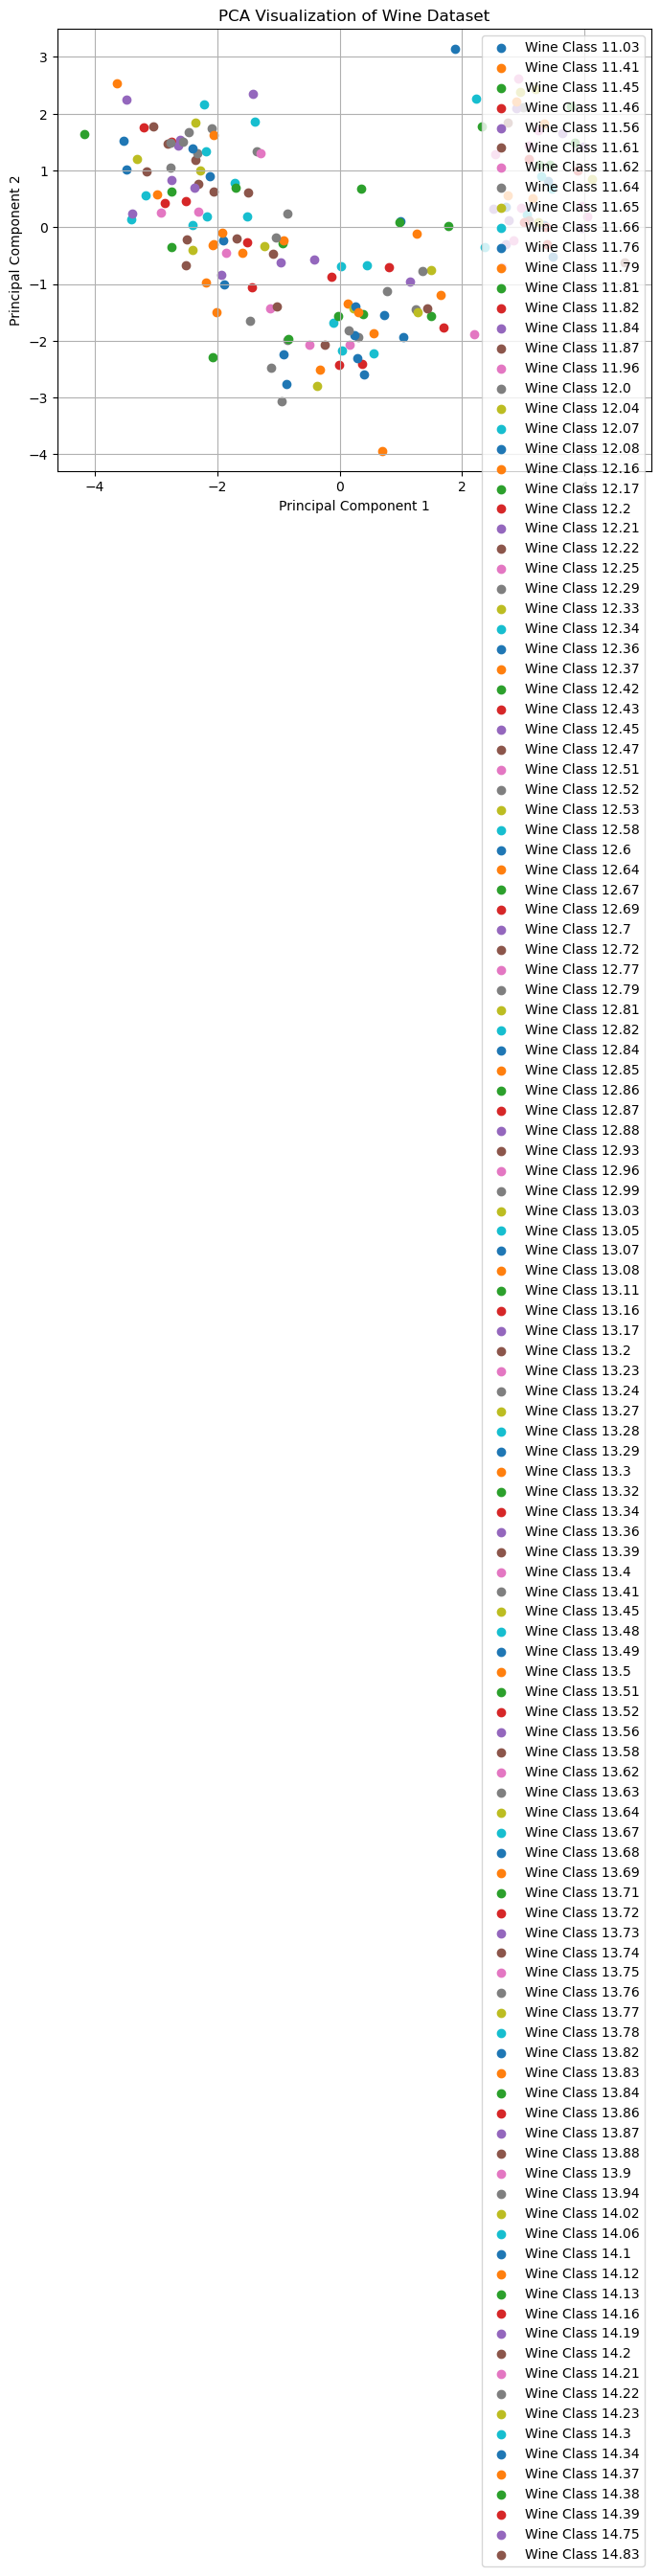

In [2]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Step 1: Load the Wine dataset
# url = "https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv"
# dataset = pd.read_csv(url)
# dataset.to_csv("Wine.csv", index = False)

dataset = pd.read_csv("Wine.csv")
# Step 2: Separate features and target
# First column is the target (wine class)
X = dataset.iloc[:, 1:].values
y = dataset.iloc[:, 0].values

print("Original Dataset Shape:", X.shape)

# Step 3: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply PCA to reduce dimensions to 3
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

# Step 5: Display transformed data
print("\nDataset after PCA:")
print(X_pca[:5])

print("\nReduced Dataset Shape:", X_pca.shape)

# Display explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Step 6: Visualize the data using first two principal components
plt.figure(figsize=(8, 6))

for wine_class in np.unique(y):
    plt.scatter(
        X_pca[y == wine_class, 0],
        X_pca[y == wine_class, 1],
        label=f"Wine Class {wine_class}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()
